In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [3]:
import os 
import librosa
import matplotlib.pyplot as plt 

## EDA

### Train data

In [4]:
#dataset structure
!ls /kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/blues/blues.00000

bass.wav  drums.wav  other.wav	vocals.wav


In [5]:
# no. of songs in each genre 
genre_stems = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
song_count = {}
for g in os.listdir(genre_stems):
    genre_path = os.path.join(genre_stems,g)
    songs = os.listdir(genre_path)
    song_count[g] = len(songs)
song_count
    


{'disco': 100,
 'metal': 100,
 'reggae': 100,
 'blues': 100,
 'rock': 100,
 'classical': 100,
 'jazz': 100,
 'hiphop': 100,
 'country': 100,
 'pop': 100}

In [6]:
# audio lengths
durations = []
gen_dir = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
for g in os.listdir(gen_dir):
    genre_path = os.path.join(gen_dir,g)
    for song in os.listdir(genre_path):
        song_path = os.path.join(genre_path,song)
        for stems in os.listdir(song_path):
            stem_path = os.path.join(song_path,stems)
            duration = librosa.get_duration(path=stem_path)
            durations.append(duration)
print(np.max(durations),np.min(durations))


30.648888888888887 29.931972789115648


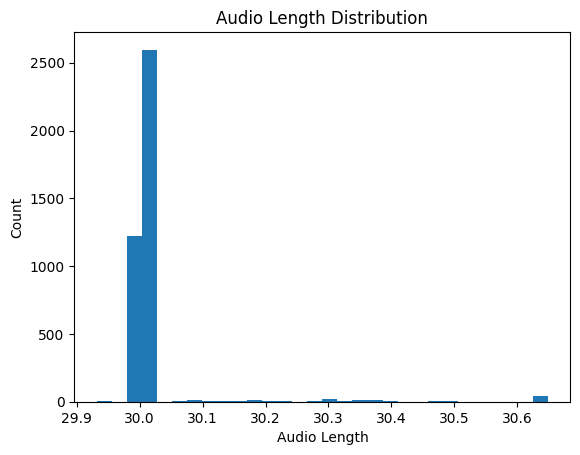

In [7]:
# length distribution
plt.hist(durations,bins=30)
plt.xlabel("Audio Length")
plt.ylabel("Count")
plt.title("Audio Length Distribution")
plt.show()

In [8]:
# any silence in a file
path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/blues/blues.00000"
for stem in os.listdir(path):
    stem_path = os.path.join(path,stem)
    y,_ = librosa.load(stem_path,sr=None)
    rms = librosa.feature.rms(y=y)[0]
    silence_ratio = np.mean(rms<0.01)
    print(f"{stem}: {silence_ratio*100:.2f}% silent")

drums.wav: 16.74% silent
vocals.wav: 20.38% silent
bass.wav: 10.17% silent
other.wav: 11.99% silent


In [12]:
# different sr
path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
rates = []
for genre in os.listdir(path):
    genre_path = os.path.join(path,genre)
    for song in os.listdir(genre_path):
        song_path = os.path.join(genre_path,song)
        for stem in os.listdir(song_path):
            stem_path = os.path.join(song_path,stem)
            y,sr = librosa.load(stem_path,sr=None)
            rates.append({
                'genre': genre,
                'song': song,
                'stem': stem,
                'sr' : sr
            })
df = pd.DataFrame(rates)
df['sr'].value_counts()
    

sr
44100    4000
Name: count, dtype: int64

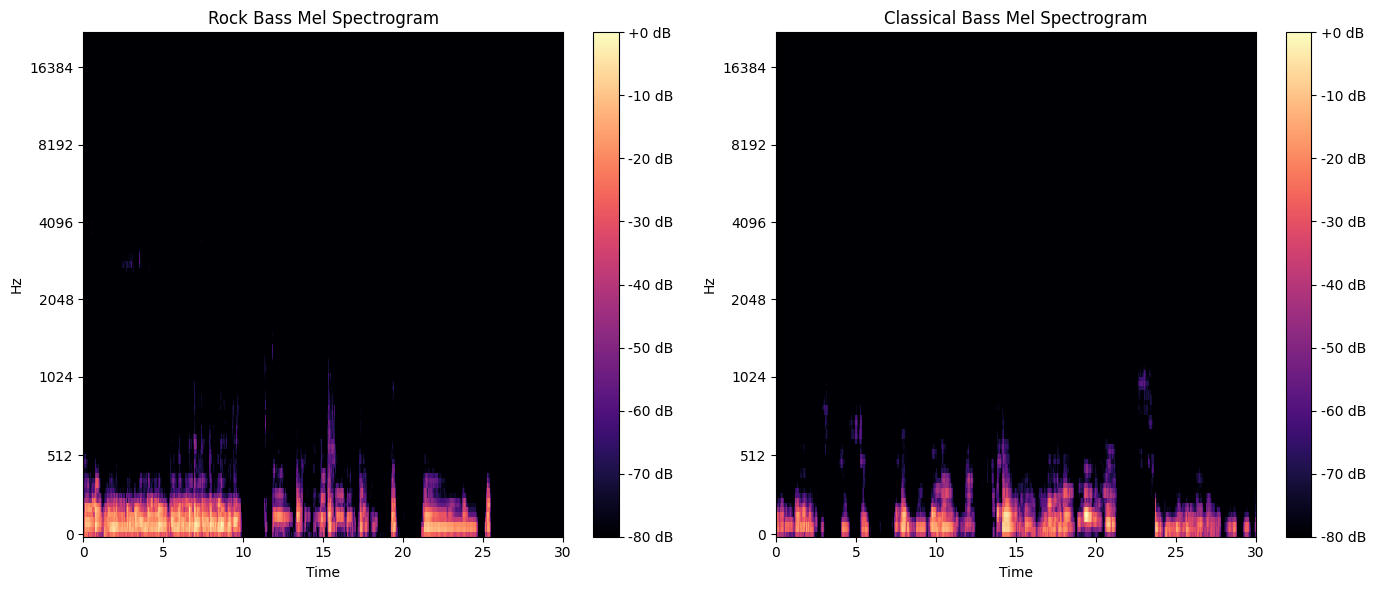

In [16]:
# melspectrogram of rock bass vs classical bass
rock_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/rock/rock.00000/bass.wav"
classical_path = "/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems/classical/classical.00000/bass.wav"

#load audio
y_rock,sr_rock = librosa.load(rock_path,sr=None)
y_classical,sr_classical = librosa.load(classical_path,sr=None)

# compute mel
rock = librosa.feature.melspectrogram(y=y_rock,sr=sr_rock,n_mels=128,hop_length=512)
rock_db = librosa.power_to_db(rock,ref=np.max)

classical = librosa.feature.melspectrogram(y=y_classical,sr=sr_classical,n_mels=128,hop_length=512)
classical_db = librosa.power_to_db(classical, ref=np.max)

plt.figure(figsize=(14, 6))

# Rock bass
plt.subplot(1, 2, 1)
librosa.display.specshow(rock_db, sr=sr_rock,hop_length= 512, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title('Rock Bass Mel Spectrogram')

# Classical bass
plt.subplot(1, 2, 2)
librosa.display.specshow(classical_db, sr=sr_classical, hop_length=512, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title('Classical Bass Mel Spectrogram')

plt.tight_layout()
plt.show()


### Noise Dataset

In [17]:
# len of noise dataset
len(os.listdir("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio"))

2000

In [18]:
# noise metadata
meta = pd.read_csv("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/meta/esc50.csv")
meta.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [19]:
meta["category"].value_counts()

category
dog                 40
chirping_birds      40
vacuum_cleaner      40
thunderstorm        40
door_wood_knock     40
can_opening         40
crow                40
clapping            40
fireworks           40
chainsaw            40
airplane            40
mouse_click         40
pouring_water       40
train               40
sheep               40
water_drops         40
church_bells        40
clock_alarm         40
keyboard_typing     40
wind                40
footsteps           40
frog                40
cow                 40
brushing_teeth      40
car_horn            40
crackling_fire      40
helicopter          40
drinking_sipping    40
rain                40
insects             40
laughing            40
hen                 40
engine              40
breathing           40
crying_baby         40
hand_saw            40
coughing            40
glass_breaking      40
snoring             40
toilet_flush        40
pig                 40
washing_machine     40
clock_tick          40
sn

### Test data

In [20]:
# len of test dataset
len(os.listdir("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/mashups"))

3020

In [21]:
test_data = pd.read_csv("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/test.csv")
test_data.head()

,id,filename
0,1,mashups/song0001.wav
1,2,mashups/song0002.wav
2,3,mashups/song0003.wav
3,4,mashups/song0004.wav
4,5,mashups/song0005.wav


In [22]:
sample = pd.read_csv("/kaggle/input/jan-2026-dl-gen-ai-project/messy_mashup/sample_submission.csv")
sample

,id,genre
0,1,jazz
1,2,blues
2,3,classical
3,4,pop
4,5,disco
...,...,...
3015,3016,pop
3016,3017,blues
3017,3018,jazz
3018,3019,rock
